# T07 — The fall-of-potential measurement

The grounding impedance of a substation is measured with the
fall-of-potential (three-pole) method: an earth tester drives a test
current $I$ between the earthing system **E** and an auxiliary current
electrode **H** (German *Hilfserder*) at a distance $d$, and measures
the voltage between E and a potential probe **S** (*Sonde*) placed
between them. The reading is

$$
Z_\mathrm{meas} = \frac{\varphi_E - \varphi_S}{I}.
$$

It equals the true impedance against remote earth only if S sits at
the right place. This tutorial simulates the measurement, derives the
classical 61.8 % rule and checks it against the field solution, and
then adds the measurement leads of a real instrument.

**You will learn**

- how to model a test current that returns through an auxiliary
  electrode (`return_to`);
- how to read a simulated earth tester (`gf.measured_impedance`) and
  the two-pole reading (`input_impedance`);
- how far the auxiliary electrode must be, and where the probe
  belongs;
- how leads ending on the instrument are modelled with junction nodes,
  and how inductive coupling between the leads enters the reading.

Runtime: about 20 s.

## The 61.8 % rule in one line

Treat E as a hemisphere of radius $r$ with $Z_E = \rho/(2\pi r)$ and H
as a small hemisphere at distance $d$. The test current leaves E and
returns into H, so the potentials of E and of a surface point S at
distance $x$ from E are

$$
\varphi_E = \frac{\rho I}{2\pi}\Bigl(\frac1r - \frac1d\Bigr),\qquad
\varphi_S = \frac{\rho I}{2\pi}\Bigl(\frac1x - \frac1{d - x}\Bigr),
$$

and the reading carries the error

$$
Z_\mathrm{meas} - Z_E = \frac{\rho}{2\pi}\Bigl(-\frac1d - \frac1x + \frac1{d-x}\Bigr).
$$

It vanishes for $x^2 + xd - d^2 = 0$, i.e. $x = \frac{\sqrt5 - 1}{2}\,d
\approx 0.618\,d$ (Tagg, 1964). With the probe in the middle,
$x = d/2$, the error is $-\rho/(2\pi d)$: it falls only with $1/d$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np

import groundfield as gf

print("groundfield", gf.__version__)

RHO = 100.0  # Ohm m
ENGINE = gf.create_engine(segment_length=0.5, frequencies=[50.0])


def measurement_world(d=None, x=None):
    # Station ring E; optional auxiliary electrode H at distance d and probe rod S at x.
    world = gf.create_world(soil=gf.HomogeneousSoil(rho=RHO))
    gf.create_electrode(
        world, "ring", name="station", center=(0.0, 0.0, 0.7), radius=2.0
    )
    if d is not None:
        gf.create_electrode(
            world, "rod", name="aux", position=(d, 0.0, 0.0), length=1.5
        )
    if x is not None:
        gf.create_electrode(
            world, "rod", name="probe", position=(x, 0.0, 0.0), length=0.5
        )
    # The test current flows into the station and returns through H.
    gf.create_source(
        world,
        attached_to="station",
        return_to="aux" if d is not None else None,
        magnitude=1.0,
    )
    return world


# Reference: the station against remote earth (no auxiliary electrode).
z_remote = ENGINE.solve(measurement_world()).input_impedance()[0].real
print(f"station against remote earth: Z_E = {z_remote:.5f} Ohm")

groundfield 2026.11.0


station against remote earth: Z_E = 13.22145 Ohm


## Simulating the instrument

`create_source(..., return_to="aux")` makes the source a two-terminal
current source: $+I$ enters the station, $-I$ leaves through the
auxiliary electrode, and the leakage currents of all electrodes add up
to zero. `gf.measured_impedance(result, probe=...)` returns the
three-pole reading for a probe electrode (or junction);
`result.input_impedance()` is the two-pole reading between E and H.

In [2]:
d = 200.0
result = ENGINE.solve(measurement_world(d, 0.618 * d))
z_meas = gf.measured_impedance(result, probe="probe")[0].real
z_two_pole = result.input_impedance()[0].real
leakage = {name: i[0].real for name, i in result.electrode_currents.items()}

print("leakage currents in A:", {k: round(v, 12) for k, v in leakage.items()})
print(
    f"three-pole reading, probe at 61.8 %: {z_meas:.5f} Ohm ({z_meas / z_remote - 1:+.1e} against Z_E)"
)
print(f"two-pole reading E-H:               {z_two_pole:.5f} Ohm")

leakage currents in A: {'station': 1.0, 'aux': -1.0, 'probe': 0.0}
three-pole reading, probe at 61.8 %: 13.22140 Ohm (-3.6e-06 against Z_E)
two-pole reading E-H:               77.69769 Ohm


In [3]:
assert abs(sum(leakage.values())) < 1e-12
assert abs(z_meas / z_remote - 1.0) < 1e-4

The two-pole reading contains the auxiliary electrode as well. With
the 2 × 2 matrix of the two electrodes (each fed alone, the other one
floating), reciprocity gives the two-pole impedance as
$Z_{EE} - Z_{EH} - Z_{HE} + Z_{HH}$ — a second way to obtain the same
number:

In [4]:
def potentials(fed):
    world = gf.create_world(soil=gf.HomogeneousSoil(rho=RHO))
    gf.create_electrode(
        world, "ring", name="station", center=(0.0, 0.0, 0.7), radius=2.0
    )
    gf.create_electrode(world, "rod", name="aux", position=(d, 0.0, 0.0), length=1.5)
    gf.create_source(world, attached_to=fed, magnitude=1.0)
    p = ENGINE.solve(world).electrode_potentials
    return p["station"][0], p["aux"][0]


(z_ee, z_he), (z_eh, z_hh) = potentials("station"), potentials("aux")
print(f"Z_EH = {z_eh.real:.6f} Ohm, Z_HE = {z_he.real:.6f} Ohm (reciprocity)")
print(f"Z_EE - Z_EH - Z_HE + Z_HH = {(z_ee - z_eh - z_he + z_hh).real:.6f} Ohm")

Z_EH = 0.079578 Ohm, Z_HE = 0.079578 Ohm (reciprocity)
Z_EE - Z_EH - Z_HE + Z_HH = 77.697689 Ohm


In [5]:
assert abs(z_eh - z_he) < 1e-9 * abs(z_eh)
assert abs((z_ee - z_eh - z_he + z_hh).real / z_two_pole - 1.0) < 1e-9

## The fall-of-potential curve

An ideal voltmeter draws no current, so the probe can also be a plain
field point: `result.potential` on the surface between E and H gives
the whole curve from one solve. The curve has a flat part around the
61.8 % point if the auxiliary electrode is far enough; the dashed line
is the hemisphere formula above with $Z_E$ from the remote-earth
solve.

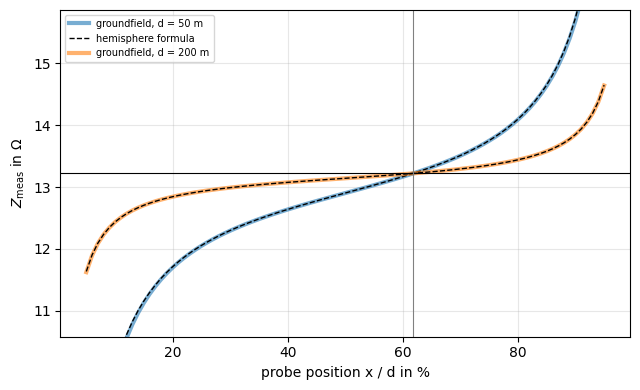

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 4.0))
for k, d_aux in enumerate((50.0, 200.0)):
    res = ENGINE.solve(measurement_world(d_aux))
    phi_e = res.electrode_potentials["station"][0]
    t = np.linspace(0.05, 0.95, 91)
    points = np.column_stack([t * d_aux, np.zeros_like(t), np.zeros_like(t)])
    curve = (phi_e - res.potential(points)).real
    hemisphere = z_remote + RHO / (2 * np.pi) * (
        -1 / d_aux - 1 / (t * d_aux) + 1 / (d_aux - t * d_aux)
    )
    ax.plot(
        100 * t,
        curve,
        color=f"C{k}",
        lw=3,
        alpha=0.6,
        label=f"groundfield, d = {d_aux:.0f} m",
    )
    ax.plot(
        100 * t, hemisphere, "k--", lw=1, label="hemisphere formula" if k == 0 else None
    )
ax.axhline(z_remote, color="k", lw=0.8)
ax.axvline(61.8, color="grey", lw=0.8)
ax.set_ylim(0.8 * z_remote, 1.2 * z_remote)
ax.set_xlabel("probe position x / d in %")
ax.set_ylabel(r"$Z_\mathrm{meas}$ in $\Omega$")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)
fig.tight_layout()

## How far must the auxiliary electrode be?

We repeat the measurement for $d$ from 20 m to 1.6 km and record the
error of the 50 % and of the 61.8 % probe position. The hemisphere
formula predicts $-\rho/(2\pi d Z_E)$ for 50 % and zero for 61.8 %.

d =     20 m: error at 50 % -6.16e-02, at 61.8 % -1.56e-03
d =     50 m: error at 50 % -2.42e-02, at 61.8 % -1.07e-04
d =    100 m: error at 50 % -1.20e-02, at 61.8 % -1.63e-05
d =    200 m: error at 50 % -6.02e-03, at 61.8 % -3.49e-06
d =    400 m: error at 50 % -3.01e-03, at 61.8 % -1.16e-06
d =    800 m: error at 50 % -1.50e-03, at 61.8 % -5.09e-07
d =   1600 m: error at 50 % -7.52e-04, at 61.8 % -2.45e-07


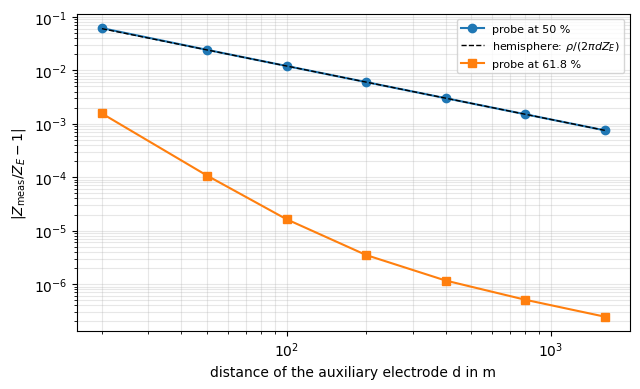

In [7]:
distances = np.array([20.0, 50.0, 100.0, 200.0, 400.0, 800.0, 1600.0])
errors = {0.5: [], 0.618: []}
for d_aux in distances:
    res = ENGINE.solve(measurement_world(d_aux))
    phi_e = res.electrode_potentials["station"][0]
    for frac in errors:
        phi_s = res.potential(np.array([[frac * d_aux, 0.0, 0.0]]))[0]
        errors[frac].append(((phi_e - phi_s).real / z_remote) - 1.0)
errors = {k: np.array(v) for k, v in errors.items()}
predicted_50 = -RHO / (2 * np.pi * distances * z_remote)

fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.loglog(distances, np.abs(errors[0.5]), "o-", label="probe at 50 %")
ax.loglog(
    distances,
    np.abs(predicted_50),
    "k--",
    lw=1,
    label=r"hemisphere: $\rho/(2\pi d Z_E)$",
)
ax.loglog(distances, np.abs(errors[0.618]), "s-", label="probe at 61.8 %")
ax.set_xlabel("distance of the auxiliary electrode d in m")
ax.set_ylabel(r"$|Z_\mathrm{meas}/Z_E - 1|$")
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=8)
fig.tight_layout()
for d_aux, e50, e62 in zip(distances, errors[0.5], errors[0.618], strict=True):
    print(f"d = {d_aux:6.0f} m: error at 50 % {e50:+.2e}, at 61.8 % {e62:+.2e}")

In [8]:
far = distances >= 100.0
assert np.allclose(errors[0.5][far], predicted_50[far], rtol=0.02)
assert np.all(np.abs(errors[0.618][far]) < 1e-4)
assert np.all(np.abs(errors[0.618]) < np.abs(errors[0.5]))

The 50 % reading follows the $1/d$ law of the hemisphere formula
closely; the 61.8 % reading is far better at every distance — its
residual comes from the finite size of the station, which the
hemisphere picture ignores. For an extended earthing system (a whole
LV network) the "electrical centre" is not known, and both the
distance and the probe position need more care; tutorial
[T06](T06_tn_network_synthetic_and_osm.ipynb) builds such networks.

## Leads that end on the instrument

A real earth tester stands at the station and is connected to H and S
by long leads. Electrically, the end of a lead at the instrument is a
*node without soil contact*. `groundfield` models it as a
**junction** (`gf.create_junction`): a network node that takes part
in Kirchhoff's law but leaks no current. The generator
`TnNetworkGenerator` builds a whole measurement set-up this way: the
feed lead runs from the junction `meas_H` to the auxiliary electrode,
the probe lead from `meas_S` to the probe, and the source drives the
test current between the station and `meas_H`.
`gf.measured_impedance(result)` then reads $\varphi_E - \varphi_S$ at
the instrument terminal `meas_S`.

Resistive leads must not change the three-pole reading (the voltmeter
draws no current), while the feed-lead resistance adds to the
two-pole reading:

In [9]:
from groundfield.generators import (
    HomogeneousSoilSpec,
    MeasurementInjectionConfig,
    MeasurementProbeConfig,
    MeasurementSetupConfig,
    TnNetworkConfig,
    TnNetworkGenerator,
    overhead_lead,
)


def tn_measurement(feed=None, probe_lead=None, d_aux=150.0, probe_xy=None):
    # Three houses on a PEN, measured from the substation with optional leads.
    cfg = TnNetworkConfig(
        soil=HomogeneousSoilSpec(rho=RHO),
        building_counts={"residential": 3},
        measurement=MeasurementSetupConfig(
            injection=MeasurementInjectionConfig(
                position_xy=(d_aux, 0.0), feed_lead=feed
            ),
            probe=MeasurementProbeConfig(
                position_xy=probe_xy or (0.618 * d_aux, 0.0), lead=probe_lead
            ),
        ),
    )
    return TnNetworkGenerator(cfg, seed=0).build()


engine = gf.create_engine(segment_length=0.5, frequencies=[50.0])
resistive = overhead_lead(inductance_model=None)  # 0.1 m above ground, R only
readings = {}
for label, kwargs in {
    "no leads": {},
    "probe lead": {"probe_lead": resistive},
    "feed lead": {"feed": resistive},
    "both leads": {"feed": resistive, "probe_lead": resistive},
}.items():
    world = tn_measurement(**kwargs)
    res = engine.solve(world)
    readings[label] = (gf.measured_impedance(res)[0], res.input_impedance()[0], world)
    print(
        f"{label:10s}: Z_meas = {readings[label][0].real:.6f} Ohm, two-pole E-H = {readings[label][1].real:.6f} Ohm, "
        f"junctions {[j.name for j in world.junctions]}"
    )
feed_resistance = (
    readings["feed lead"][2].get_conductor("meas_feed_lead").series_resistance
)
print(f"resistance of the feed lead: {feed_resistance:.6f} Ohm")

no leads  : Z_meas = 1.650609 Ohm, two-pole E-H = 61.063546 Ohm, junctions []
probe lead: Z_meas = 1.650609 Ohm, two-pole E-H = 61.063546 Ohm, junctions ['meas_S']


feed lead : Z_meas = 1.650609 Ohm, two-pole E-H = 61.095631 Ohm, junctions ['meas_H']
both leads: Z_meas = 1.650609 Ohm, two-pole E-H = 61.095631 Ohm, junctions ['meas_H', 'meas_S']
resistance of the feed lead: 0.032086 Ohm


In [10]:
z0 = readings["no leads"][0]
assert all(abs(z - z0) < 1e-9 * abs(z0) for z, *_ in readings.values())
assert (
    abs((readings["feed lead"][1] - readings["no leads"][1]).real - feed_resistance)
    < 1e-9
)

### Inductive coupling between the leads

At 50 Hz the test current in the feed lead induces a voltage in a
probe lead that runs beside it; the reading gains an imaginary part.
We give both leads their inductance (`overhead_lead()` uses the
Neumann model) and move the probe sideways, so that its lead leaves
the feed lead at a growing angle. The earth return is the Sommerfeld
model with the faster tabulated assembly. The coupling falls as the
leads separate — the reason why probe leads are laid at an angle to
the feed lead in practice.

probe    0 m off the axis: Z_meas = 1.65100+0.05414j Ohm


probe    5 m off the axis: Z_meas = 1.65003+0.02370j Ohm


probe   10 m off the axis: Z_meas = 1.64720+0.01971j Ohm


probe   20 m off the axis: Z_meas = 1.63679+0.01572j Ohm


probe   50 m off the axis: Z_meas = 1.58976+0.01064j Ohm


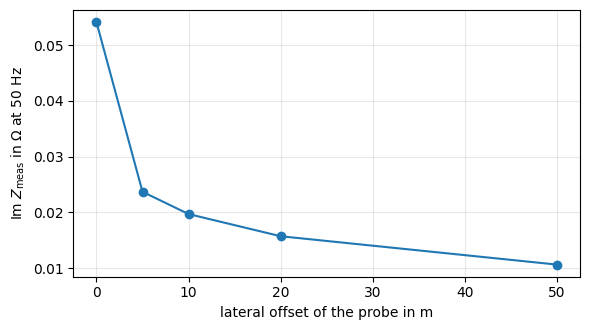

In [11]:
engine_l = gf.create_engine(
    segment_length=0.5, frequencies=[50.0], sommerfeld_assembly="tabulated"
)
offsets = [0.0, 5.0, 10.0, 20.0, 50.0]
coupled = []
for dy in offsets:
    world = tn_measurement(
        feed=overhead_lead(), probe_lead=overhead_lead(), probe_xy=(92.7, dy)
    )
    coupled.append(gf.measured_impedance(engine_l.solve(world))[0])
    print(f"probe {dy:4.0f} m off the axis: Z_meas = {coupled[-1]:.5f} Ohm")

fig, ax = plt.subplots(figsize=(6.0, 3.4))
ax.plot(offsets, [z.imag for z in coupled], "o-")
ax.set_xlabel("lateral offset of the probe in m")
ax.set_ylabel(r"Im $Z_\mathrm{meas}$ in $\Omega$ at 50 Hz")
ax.grid(alpha=0.3)
fig.tight_layout()

In [12]:
im = np.array([z.imag for z in coupled])
assert np.all(im > 0) and np.all(np.diff(im) < 0)

## Summary

- A measurement is a two-terminal source: `create_source(...,
  return_to=...)`. `gf.measured_impedance` is the three-pole reading,
  `input_impedance()` the two-pole reading.
- With a compact earthing system the 61.8 % rule removes the error of
  a finite auxiliary distance almost completely; the 50 % position
  leaves an error $\rho/(2\pi d Z_E)$.
- Leads end on junction nodes at the instrument; resistive leads do
  not change the three-pole reading, inductive coupling between feed
  and probe lead does.

**Next:** [T08 — touch and step voltages](T08_touch_and_step_assessment.ipynb).